# TDVP (RBM) vs exact dynamics: baseline and accumulated error

Spin-1/2 chain with all-to-all XX couplings and a field along Z:

$$H = h \sum_i Z_i + \sum_{i<j} J_{ij} X_i X_j, \qquad J_{ij} = 1.$$

The initial state is a complex RBM ($\alpha = 1$) with seeded parameters (`SEED = 45`), held exactly as a `FullSumState`. Its vector is also the initial condition of the exact evolution $|\psi(t)\rangle = e^{-iHt}|\psi(0)\rangle$ (`scipy.sparse.linalg.expm_multiply`), so every difference comes from the TDVP projection and the integrator.

TDVP settings: RK45 with `dt = 1e-3` (forced onto the same time grid as ED), `QGTJacobianDense(holomorphic=True)` with `diag_shift = 1e-6`, SVD solver. With `diag_shift = 1e-4` the regularization alone gives an error of about $10^{-3}$ on $\langle Z \rangle$ at $t = 0.5$.

The notebook has three parts:

1. **Baseline** (N = 6, h = 10, T = 5): $\langle Z \rangle$ along the run, as in issue #2. The same comparison at $T = 0.5$ is the CI test `tests/QELM/NQS/dynamics/test_tdvp_baseline.py`.
2. **All tracked observables** for one run: energy, local magnetizations $\langle X_i \rangle$ and $\langle Z_i \rangle$, half-chain entanglement entropy, fidelity.
3. **Accumulated error against the field** $h$, for N = 4, 6 and 8.

Figures go to `outputs/tdvp_vs_ed_baseline/<timestamp>/plots/`.

In [1]:
import numpy as np

from QELM.NQS.dynamics import (
    BASELINE_SEED,
    ERROR_KEYS,
    FieldSweep,
    TDVPSettings,
    accumulated_error_vs_field,
    compare_with_exact,
    tdvp_vs_exact,
)
from QELM.NQS.paths import experiment_paths
from QELM.NQS.utils.makeplots import plot_exact_vs_tdvp, plot_field_scan
from QELM.NQS.utils.outputs import find_repo_root

ROOT = find_repo_root()
J = 1.0
DT = 1e-3
SEED = BASELINE_SEED  # 45
SETTINGS = TDVPSettings(dt=DT, integrator="RK45", diag_shift=1e-6, linear_solver="svd")

paths = experiment_paths(
    experiment_name="tdvp_vs_ed_baseline", outputs_root=ROOT / "outputs"
)
print("run folder:", paths.root)

/home/claude/QRC-issue23/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


∣NK⟩ Tip: 😍 Love? 😡 Hate? these tips? Let us know at https://forms.gle/ej8eDGFRu2mww5mQ9

run folder: /home/claude/QRC-issue23/outputs/tdvp_vs_ed_baseline/2026-10-22_13-31-59_746bc0a8


## 1. Baseline: N = 6, h = 10, T = 5

In [2]:
result = tdvp_vs_exact(
    n_spins=6, h=10.0, J=J, T=5.0, seed=SEED, settings=SETTINGS, paths=paths
)
print("time points (ED, TDVP):", len(result.times), len(result.tdvp_times))
print(f"max |<Z>_TDVP - <Z>_ED| = {result.max_abs_error:.2e}")
print(f"final fidelity |<psi_ED(T)|psi_TDVP(T)>|^2 = {result.final_fidelity:.6f}")
drift = abs(result.tdvp_energy - result.exact_energy[0]).max()
print(f"energy drift max |E_TDVP(t) - E(0)| = {drift:.2e}")

time points (ED, TDVP): 5001 5001
max |<Z>_TDVP - <Z>_ED| = 1.47e-04
final fidelity |<psi_ED(T)|psi_TDVP(T)>|^2 = 0.999997
energy drift max |E_TDVP(t) - E(0)| = 7.43e-07


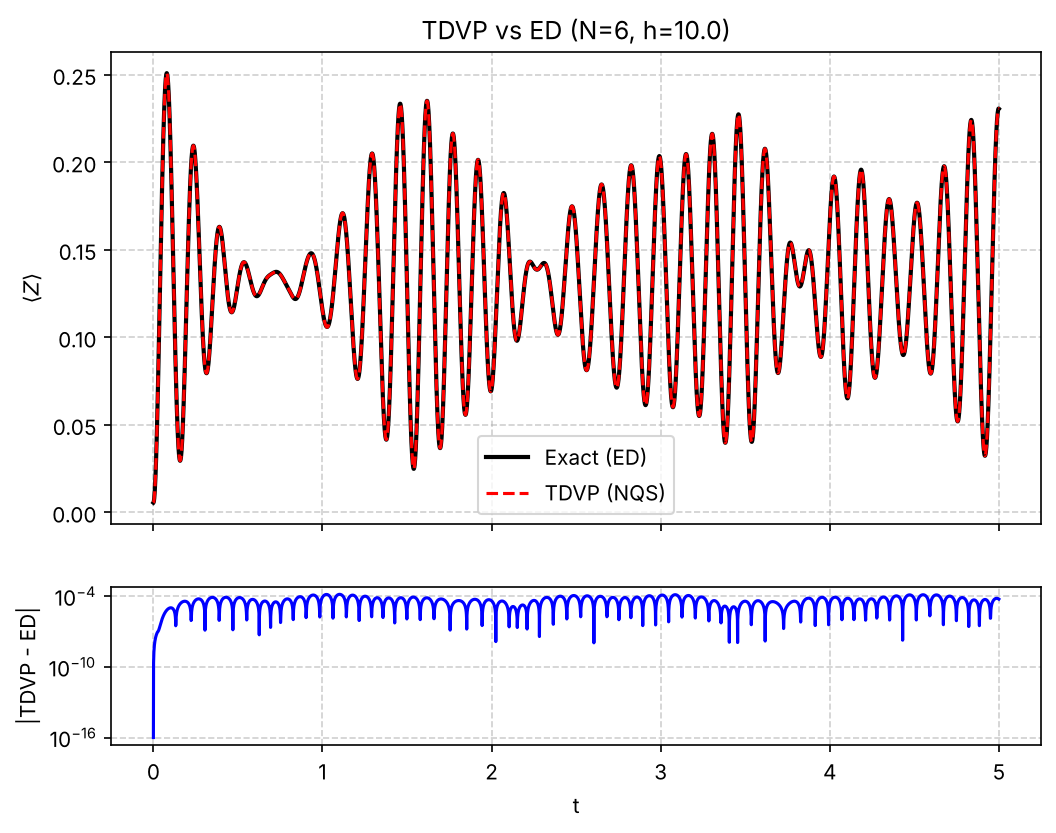

In [3]:
from IPython.display import Image, display

display(Image(filename=str(result.plot)))

## 2. All tracked observables for one run

`compare_with_exact` records the TDVP state vector on the grid (`run_tdvp(..., record_states=True)`) and evaluates every observable on both trajectories with the same code:

- the energy $\langle H \rangle$ (conserved by both dynamics, up to the regularization for TDVP);
- the local magnetizations $\langle X_i \rangle$ and $\langle Z_i \rangle$;
- the half-chain von Neumann entropy $S = -\mathrm{Tr}\,\rho_A \ln \rho_A$ of sites $0, \dots, N/2 - 1$, in nats (at most $\frac{N}{2}\ln 2$);
- the fidelity $F(t) = |\langle \psi_\mathrm{ED}(t) | \psi_\mathrm{TDVP}(t) \rangle|^2$.

Here N = 6, h = 1, T = 2: at $h = J$ the field and the couplings compete.

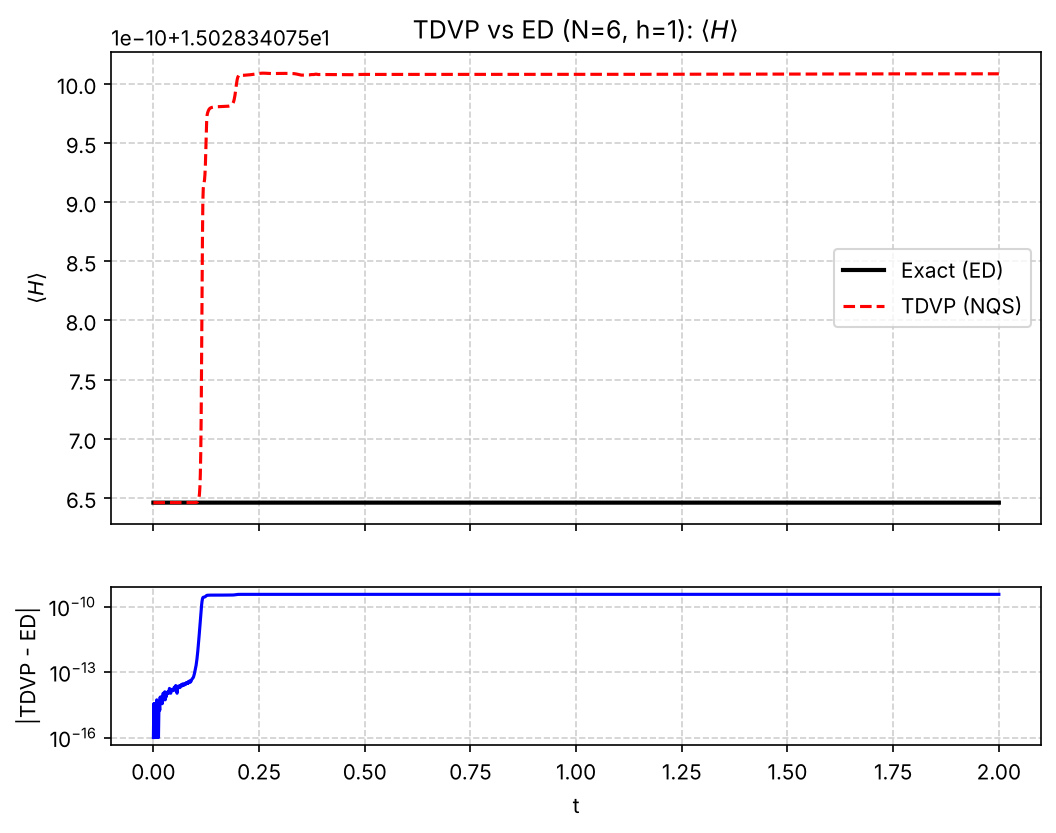

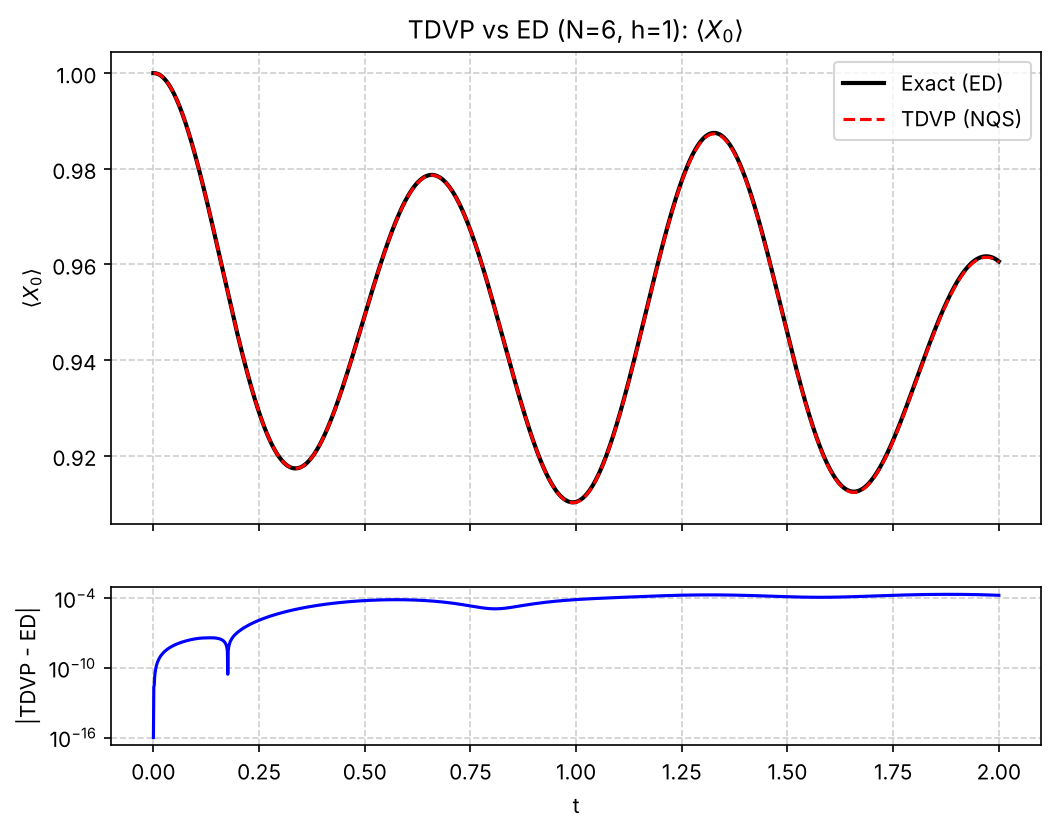

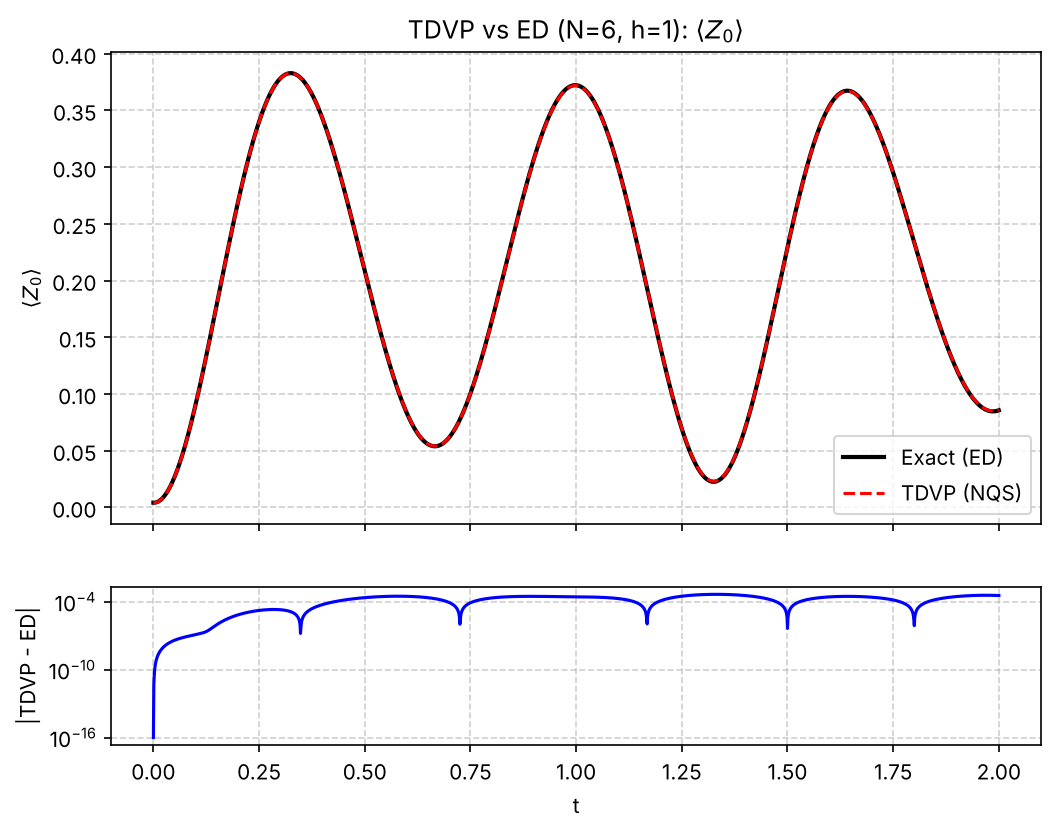

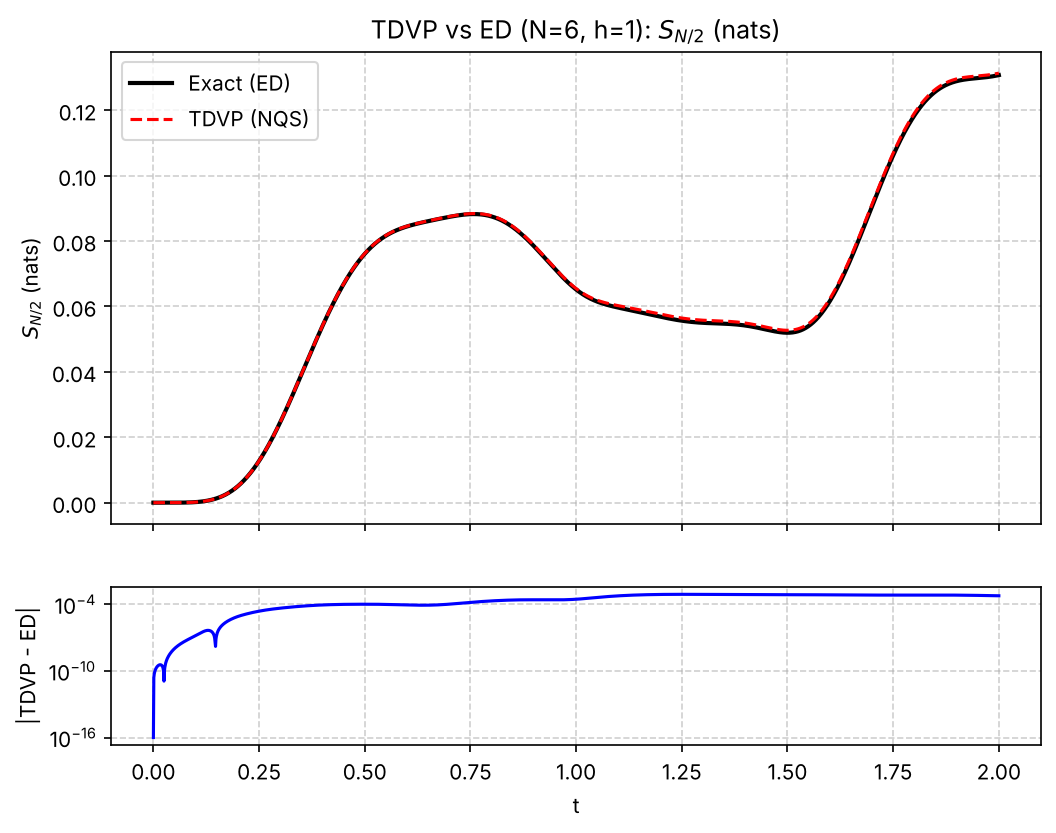

min fidelity over the run: 0.999997
accumulated error           energy: 6.802e-10   (time average 3.401e-10)
accumulated error  magnetization_z: 3.777e-04   (time average 1.889e-04)
accumulated error          sigma_x: 1.952e-04   (time average 9.759e-05)
accumulated error          sigma_z: 3.784e-04   (time average 1.892e-04)
accumulated error          entropy: 7.974e-04   (time average 3.987e-04)
accumulated error       infidelity: 5.667e-06   (time average 2.833e-06)


In [4]:
example = compare_with_exact(n_spins=6, h=1.0, J=J, T=2.0, seed=SEED, settings=SETTINGS)
t = example.times
panels = {
    "energy": (example.exact.energy, example.tdvp.energy, r"$\langle H \rangle$"),
    "sigma_x0": (
        example.exact.sigma_x[:, 0],
        example.tdvp.sigma_x[:, 0],
        r"$\langle X_0 \rangle$",
    ),
    "sigma_z0": (
        example.exact.sigma_z[:, 0],
        example.tdvp.sigma_z[:, 0],
        r"$\langle Z_0 \rangle$",
    ),
    "entropy": (example.exact.entropy, example.tdvp.entropy, r"$S_{N/2}$ (nats)"),
}
for name, (exact, tdvp, label) in panels.items():
    path = plot_exact_vs_tdvp(
        t,
        exact,
        t,
        tdvp,
        filename=f"example_{name}.png",
        directory=paths.plots,
        ylabel=label,
        title=f"TDVP vs ED (N=6, h=1): {label}",
    )
    display(Image(filename=str(path)))

print(f"min fidelity over the run: {example.fidelity.min():.6f}")
for key, value in example.accumulated_errors().items():
    print(
        f"accumulated error {key:>16}: {value:.3e}   (time average {value / t[-1]:.3e})"
    )

## 3. Accumulated absolute error against the field

For each observable $O$, the accumulated absolute error over the run is

$$\mathcal{E}_O(T) = \int_0^T \big|\langle O \rangle_\mathrm{TDVP}(t) - \langle O \rangle_\mathrm{ED}(t)\big|\, dt$$

(trapezoidal rule on the `dt = 1e-3` grid, units of $[O] \times$ time; divide by $T$ for the time average). For the local magnetizations the error is averaged over sites, $\frac{1}{N} \sum_i \mathcal{E}_{X_i}$. The error of the mean magnetization $\frac{1}{N}\sum_i Z_i$ is at most the site-averaged one (triangle inequality). The infidelity is accumulated as $\int_0^T (1 - F)\, dt$.

Every run starts from the same seeded RBM; only $h$ changes. A sweep takes about 10 to 25 minutes per N on a laptop CPU, so each one is cached in `outputs/tdvp_vs_ed_error_scan/` (gitignored). Set `RECOMPUTE = True` to run them again.

In [5]:
SIZES = (4, 6, 8)
FIELDS = (0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0)
T_SCAN = 2.0
RECOMPUTE = False

cache = ROOT / "outputs" / "tdvp_vs_ed_error_scan"
sweeps: dict[int, FieldSweep] = {}
for n in SIZES:
    file = cache / f"sweep_N{n}_T{T_SCAN:g}_seed{SEED}.npz"
    if file.is_file() and not RECOMPUTE:
        sweep = FieldSweep.load(file)
        assert np.allclose(sweep.fields, FIELDS) and sweep.T == T_SCAN
    else:
        sweep = accumulated_error_vs_field(
            n_spins=n, fields=FIELDS, J=J, T=T_SCAN, seed=SEED, settings=SETTINGS
        )
        sweep.save(file)
    sweeps[n] = sweep

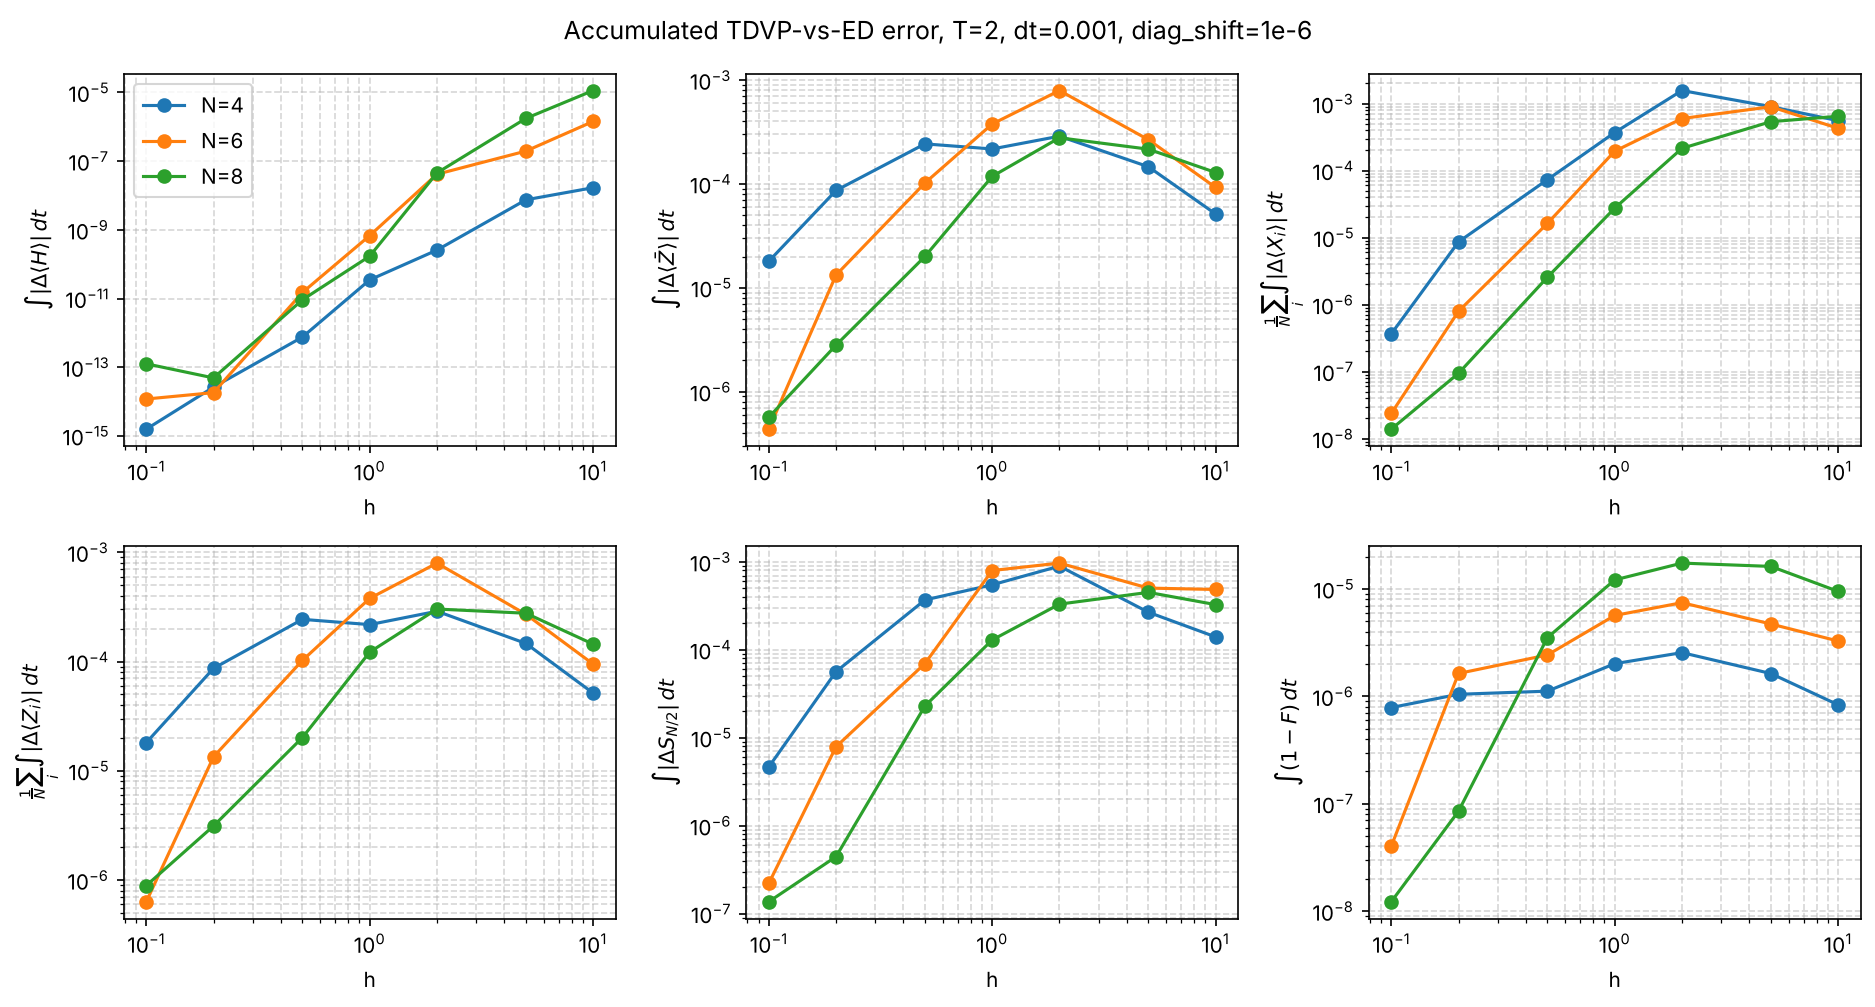

In [6]:
labels = {
    "energy": r"$\int |\Delta \langle H \rangle|\, dt$",
    "magnetization_z": r"$\int |\Delta \langle \bar Z \rangle|\, dt$",
    "sigma_x": r"$\frac{1}{N}\sum_i \int |\Delta \langle X_i \rangle|\, dt$",
    "sigma_z": r"$\frac{1}{N}\sum_i \int |\Delta \langle Z_i \rangle|\, dt$",
    "entropy": r"$\int |\Delta S_{N/2}|\, dt$",
    "infidelity": r"$\int (1 - F)\, dt$",
}
scan = plot_field_scan(
    {f"N={n}": s.fields for n, s in sweeps.items()},
    {f"N={n}": s.errors for n, s in sweeps.items()},
    panels=labels,
    filename="accumulated_error_vs_h.png",
    directory=paths.plots,
    title=f"Accumulated TDVP-vs-ED error, T={T_SCAN:g}, dt={DT:g}, diag_shift=1e-6",
)
display(Image(filename=str(scan)))

In [7]:
header = (
    f"{'N':>2} {'h':>5} " + " ".join(f"{k:>15}" for k in ERROR_KEYS) + f" {'F(T)':>10}"
)
print(header)
for n, s in sweeps.items():
    for i, h in enumerate(s.fields):
        row = " ".join(f"{s.errors[k][i]:15.3e}" for k in ERROR_KEYS)
        print(f"{n:>2} {h:5.1f} {row} {s.final_fidelity[i]:10.6f}")

 N     h          energy magnetization_z         sigma_x         sigma_z         entropy      infidelity       F(T)
 4   0.1       1.570e-15       1.801e-05       3.657e-07       1.809e-05       4.652e-06       7.871e-07   0.999999
 4   0.2       2.629e-14       8.656e-05       8.636e-06       8.660e-05       5.647e-05       1.045e-06   0.999999
 4   0.5       7.556e-13       2.432e-04       7.340e-05       2.433e-04       3.693e-04       1.118e-06   0.999999
 4   1.0       3.493e-11       2.173e-04       3.708e-04       2.177e-04       5.487e-04       2.015e-06   0.999999
 4   2.0       2.575e-10       2.884e-04       1.570e-03       2.886e-04       8.940e-04       2.555e-06   0.999999
 4   5.0       7.492e-09       1.465e-04       9.020e-04       1.465e-04       2.676e-04       1.631e-06   0.999999
 4  10.0       1.689e-08       5.137e-05       5.561e-04       5.138e-05       1.402e-04       8.338e-07   1.000000
 6   0.1       1.185e-14       4.356e-07       2.370e-08       6.334e-07

### How much does the exact state move?

A small accumulated error only means something if the exact observable moves. The seeded RBM starts close to $|{+}\rangle^{\otimes N}$ (NetKet initializes its parameters with width 0.01, so $\psi(s)$ is almost uniform and $\langle X_i \rangle \approx 1$), which is an eigenstate of the coupling term $\sum_{i<j} X_i X_j$. The next cell measures the motion of the exact trajectory, $\frac{1}{N}\sum_i \int_0^T |\langle X_i \rangle_\mathrm{ED}(t) - \langle X_i \rangle_\mathrm{ED}(0)|\, dt$ (ED only, a few seconds), and the error of $\langle X_i \rangle$ relative to it.

N=4: <X_i>(0) = [1.     0.9998 0.9999 0.9997]


N=6: <X_i>(0) = [1.     0.9998 0.9999 0.9997 0.9997 1.    ]


N=8: <X_i>(0) = [1.     0.9998 0.9999 0.9997 0.9997 1.     1.     0.9998]


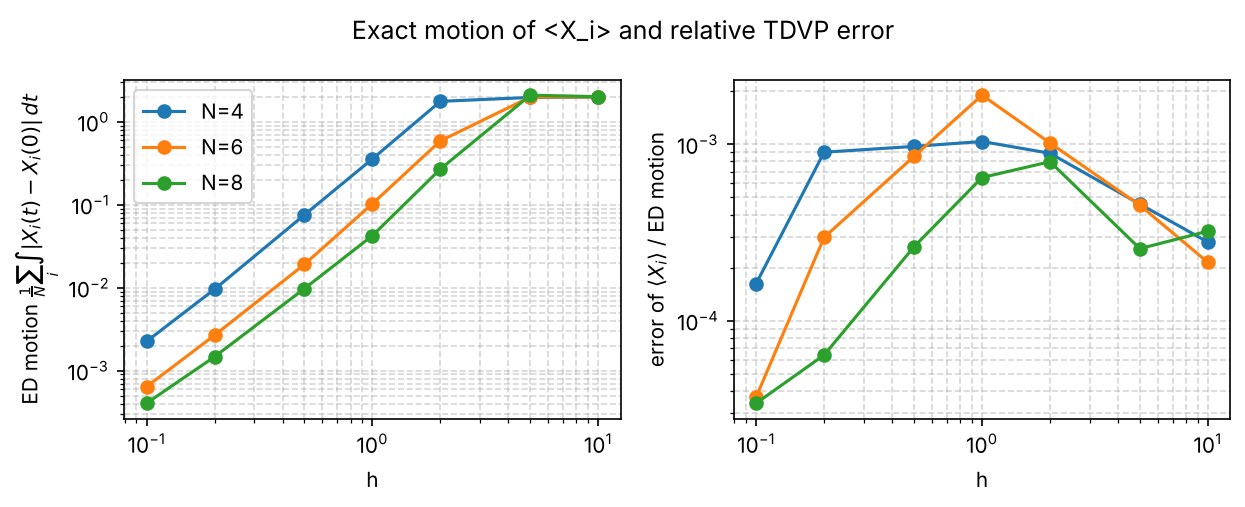

In [8]:
from QELM.NQS.dynamics import (
    accumulated_absolute_error,
    exact_time_evolution,
    time_grid,
    trajectory_observables,
)
from QELM.NQS.measurements import all_to_all_xx_hamiltonian
from QELM.NQS.variational import rbm, spin_half_hilbert, variational_state

grid = time_grid(T_SCAN, DT)
motion: dict[int, np.ndarray] = {}
for n in SIZES:
    hilbert = spin_half_hilbert(n)
    psi0 = np.asarray(variational_state(hilbert, rbm(), seed=SEED).to_array())
    values = []
    for h in FIELDS:
        H = all_to_all_xx_hamiltonian(hilbert, h=h, J=J)
        x = trajectory_observables(
            exact_time_evolution(H, psi0, grid), H, hilbert
        ).sigma_x
        start = np.broadcast_to(x[0], x.shape)
        values.append(np.mean(accumulated_absolute_error(grid, x, start)))
    motion[n] = np.asarray(values)
    print(f"N={n}: <X_i>(0) = {np.round(x[0], 4)}")

relative = plot_field_scan(
    {f"N={n}": s.fields for n, s in sweeps.items()},
    {
        f"N={n}": {
            "motion": motion[n],
            "relative": s.errors["sigma_x"] / motion[n],
        }
        for n, s in sweeps.items()
    },
    panels={
        "motion": r"ED motion $\frac{1}{N}\sum_i \int |X_i(t) - X_i(0)|\, dt$",
        "relative": r"error of $\langle X_i \rangle$ / ED motion",
    },
    filename="relative_error_vs_h.png",
    directory=paths.plots,
    title="Exact motion of <X_i> and relative TDVP error",
)
display(Image(filename=str(relative)))

### Reading the scan

Numbers for T = 2, dt = 1e-3, `diag_shift = 1e-6`, seed 45 (table above).

- **Energy.** The accumulated energy error stays between $10^{-15}$ and $10^{-5}$, far below the other observables. Real-time TDVP with a time-independent $H$ conserves $\langle H \rangle$ up to the regularization and the integrator, so this is expected; it grows with $h$ because the energy scale grows with $h$.
- **Local magnetizations.** The site-averaged errors of $\langle X_i \rangle$ and $\langle Z_i \rangle$ peak at a few $10^{-4}$ to $1.6\times10^{-3}$ (time average below $10^{-3}$) around $h \approx 1$ to $5$, where the field and the all-to-all coupling (scale $J N/2$) compete. The error of the mean magnetization equals the site-averaged $\langle Z_i \rangle$ error almost exactly: the TDVP error is nearly uniform over sites, as the permutation-symmetric $H$ suggests.
- **Small h.** The errors fall to $10^{-7}$ to $10^{-8}$, but the relative-error plot shows why: the initial state is close to $|{+}\rangle^{\otimes N}$, an eigenstate of the coupling term, so the exact state hardly moves (left panel of the relative-error figure). Measured against that motion, the error of $\langle X_i \rangle$ stays between $3\times10^{-5}$ and $2\times10^{-3}$ over the whole scan (right panel): small $h$ is not where TDVP is accurate, it is where little happens.
- **Large h.** For $h \gg J N$ the field dominates. $h \sum_i Z_i$ alone only rotates each spin, and that motion is exactly an RBM (visible biases shifted by $-iht$, see the free-spin test), so the error decreases again even though the state moves the most. The relative error of $\langle X_i \rangle$ is then at the $10^{-4}$ level.
- **Entanglement entropy.** Its accumulated error follows the magnetizations and stays below $10^{-3}$.
- **Fidelity and N.** $\int (1 - F)\, dt$ grows with N at fixed $h$ (at $h = 2$: $2.6\times10^{-6}$, $7.5\times10^{-6}$, $1.7\times10^{-5}$ for N = 4, 6, 8), and $F(T) > 0.99998$ everywhere. With $\alpha = 1$ the RBM has $N + N + N^2$ parameters for $2^N$ amplitudes, so the projection error is expected to grow with N.

The scan depends on the initial state: a more generic RBM (`rbm(init_std=0.1)`, as in the Loschmidt echo test) would make the small-$h$ points meaningful.